In [31]:
import os

for folder, subfolders, files in os.walk("data"):
    for f in files[:3]:
        print(os.path.join(folder, f))

data\Beauty & Hygiene\Bath & Hand Wash\Bath Salts & Oils\product_data.xlsx
data\Beauty & Hygiene\Bath & Hand Wash\Bathing Accesories\product_data.xlsx
data\Beauty & Hygiene\Bath & Hand Wash\Bathing Bars & Soaps\product_data.xlsx
data\Beauty & Hygiene\Bath & Hand Wash\Body Scrubs & Exfoliants\product_data.xlsx
data\Beauty & Hygiene\Bath & Hand Wash\Hand Wash & Sanitizers\product_data.xlsx
data\Beauty & Hygiene\Bath & Hand Wash\Shower Gel & Body Wash\product_data.xlsx
data\Beauty & Hygiene\Bath & Hand Wash\Talcum Powder\product_data.xlsx
data\Beauty & Hygiene\Feminine Hygiene\Hair Removal\product_data.xlsx
data\Beauty & Hygiene\Feminine Hygiene\Intimate Wash & Care\product_data.xlsx
data\Beauty & Hygiene\Feminine Hygiene\Panty Liners\product_data.xlsx
data\Beauty & Hygiene\Feminine Hygiene\Sanitary Napkins\product_data.xlsx
data\Beauty & Hygiene\Feminine Hygiene\Tampons & Menstrual Cups\product_data.xlsx
data\Beauty & Hygiene\Fragrances & Deos\Attar\product_data.xlsx
data\Beauty & Hygien

In [2]:
from collections import Counter

ext = Counter()
for folder, subfolders, files in os.walk("data"):
    for f in files:
        ext[os.path.splitext(f)[1]] += 1

print(ext)

Counter({'.xlsx': 157})


In [3]:
import os
import pandas as pd

# saari Excel files ka path list mein collect karna
all_files = []
for folder, subfolders, files in os.walk("data"):
    for f in files:
        if f.endswith(".xlsx"):
            all_files.append(os.path.join(folder, f))

print(len(all_files))
print(all_files[0])

157
data\Beauty & Hygiene\Bath & Hand Wash\Bath Salts & Oils\product_data.xlsx


In [4]:
df = pd.read_excel(all_files[0])
print(df.shape)
df.head()

(80, 11)


,Category,Sub-Category,Sub-sub-Category,Product Link,EAN Code,Image Link,Brand,SKU Name,SKU Size,MRP,About the Product
0,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40147527/soulflow...,40147527,https://www.bigbasket.com/media/uploads/p/l/40...,Soulflower,Soulflower Diwali Heart Lavender Bath & Body G...,NaN,₹2000,Gift yourself or your loved ones Soulflower La...
1,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/1220827/soulflowe...,1220827,https://www.bigbasket.com/media/uploads/p/l/12...,Soulflower,Soulflower Rose Geranium Aroma Bath Salt for M...,2x500 g,₹900,Our mineral-rich sea salt is mined from the In...
2,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40120583/biotique...,8904352005008,https://www.bigbasket.com/media/uploads/p/l/40...,BIOTIQUE,BIOTIQUE Anti-Ageing After-Bath Body Oil - Car...,NaN,₹136,About the ProductThis luxurious after bath oil...
3,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40284277/beautiso...,40284277,https://www.bigbasket.com/media/uploads/p/l/40...,Beautisoul,Beautisoul Peppermint & Eucalyptus Bath Salt -...,450 g,₹399,"This product is a combination of Epsom salt, M..."
4,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40139698/nyassa-l...,&&8906056674825,https://www.bigbasket.com/media/uploads/p/l/40...,Nyassa,"Nyassa Lavander Bath Salt, 220 g",NaN,₹400,"Care for a good nights sleep, immerse yourself..."


In [5]:
print(df.columns.tolist())

['Category', 'Sub-Category', 'Sub-sub-Category', 'Product Link', 'EAN Code', 'Image Link', 'Brand', 'SKU Name', 'SKU Size', 'MRP', 'About the Product']


In [6]:
import os
import pandas as pd

frames = []
failed = []

for folder, subfolders, files in os.walk("data"):
    for f in files:
        if f.endswith(".xlsx"):
            path = os.path.join(folder, f)
            try:
                temp = pd.read_excel(path)
                temp["category"] = os.path.basename(folder)
                temp["sub_category"] = os.path.splitext(f)[0]
                frames.append(temp)
            except Exception as e:
                failed.append((path, str(e)))

df = pd.concat(frames, ignore_index=True)

print("Files joined:", len(frames))
print("Files failed:", len(failed))
print("Total shape:", df.shape)

Files joined: 157
Files failed: 0
Total shape: (57013, 13)


In [7]:
df.head()

,Category,Sub-Category,Sub-sub-Category,Product Link,EAN Code,Image Link,Brand,SKU Name,SKU Size,MRP,About the Product,category,sub_category
0,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40147527/soulflow...,40147527,https://www.bigbasket.com/media/uploads/p/l/40...,Soulflower,Soulflower Diwali Heart Lavender Bath & Body G...,NaN,₹2000,Gift yourself or your loved ones Soulflower La...,Bath Salts & Oils,product_data
1,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/1220827/soulflowe...,1220827,https://www.bigbasket.com/media/uploads/p/l/12...,Soulflower,Soulflower Rose Geranium Aroma Bath Salt for M...,2x500 g,₹900,Our mineral-rich sea salt is mined from the In...,Bath Salts & Oils,product_data
2,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40120583/biotique...,8904352005008,https://www.bigbasket.com/media/uploads/p/l/40...,BIOTIQUE,BIOTIQUE Anti-Ageing After-Bath Body Oil - Car...,NaN,₹136,About the ProductThis luxurious after bath oil...,Bath Salts & Oils,product_data
3,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40284277/beautiso...,40284277,https://www.bigbasket.com/media/uploads/p/l/40...,Beautisoul,Beautisoul Peppermint & Eucalyptus Bath Salt -...,450 g,₹399,"This product is a combination of Epsom salt, M...",Bath Salts & Oils,product_data
4,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40139698/nyassa-l...,&&8906056674825,https://www.bigbasket.com/media/uploads/p/l/40...,Nyassa,"Nyassa Lavander Bath Salt, 220 g",NaN,₹400,"Care for a good nights sleep, immerse yourself...",Bath Salts & Oils,product_data


In [8]:
print(df.columns.tolist())

['Category', 'Sub-Category', 'Sub-sub-Category', 'Product Link', 'EAN Code', 'Image Link', 'Brand', 'SKU Name', 'SKU Size', 'MRP', 'About the Product', 'category', 'sub_category']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 57013 entries, 0 to 57012
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Category           57013 non-null  str   
 1   Sub-Category       57013 non-null  str   
 2   Sub-sub-Category   57013 non-null  str   
 3   Product Link       57013 non-null  str   
 4   EAN Code           55498 non-null  object
 5   Image Link         57013 non-null  str   
 6   Brand              57010 non-null  str   
 7   SKU Name           57013 non-null  str   
 8   SKU Size           11345 non-null  object
 9   MRP                45698 non-null  str   
 10  About the Product  54839 non-null  str   
 11  category           57013 non-null  str   
 12  sub_category       57013 non-null  str   
dtypes: object(2), str(11)
memory usage: 5.7+ MB


In [10]:
df = df.drop(columns=["category", "sub_category"])

df.columns = ["category", "sub_category", "sub_sub_category", "product_link",
              "ean_code", "image_link", "brand", "sku_name", "sku_size",
              "mrp", "about"]

df.head(3)

,category,sub_category,sub_sub_category,product_link,ean_code,image_link,brand,sku_name,sku_size,mrp,about
0,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40147527/soulflow...,40147527,https://www.bigbasket.com/media/uploads/p/l/40...,Soulflower,Soulflower Diwali Heart Lavender Bath & Body G...,NaN,₹2000,Gift yourself or your loved ones Soulflower La...
1,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/1220827/soulflowe...,1220827,https://www.bigbasket.com/media/uploads/p/l/12...,Soulflower,Soulflower Rose Geranium Aroma Bath Salt for M...,2x500 g,₹900,Our mineral-rich sea salt is mined from the In...
2,beauty & hygiene,bath & hand wash,bath salts & oils,https://www.bigbasket.com/pd/40120583/biotique...,8904352005008,https://www.bigbasket.com/media/uploads/p/l/40...,BIOTIQUE,BIOTIQUE Anti-Ageing After-Bath Body Oil - Car...,NaN,₹136,About the ProductThis luxurious after bath oil...


In [11]:
df["mrp"] = (df["mrp"]
             .str.replace("₹", "", regex=False)
             .str.replace(",", "", regex=False)
             .str.strip())

df["mrp"] = pd.to_numeric(df["mrp"], errors="coerce")

df["mrp"].describe()

count    45698.000000
mean       340.172939
std        643.430618
min          0.000000
25%         99.000000
50%        199.245000
75%        382.980000
max      31900.000000
Name: mrp, dtype: float64

In [12]:
print(df.isnull().sum())
print("Duplicate products:", df.duplicated(subset="product_link").sum())

category                0
sub_category            0
sub_sub_category        0
product_link            0
ean_code             1515
image_link              0
brand                   3
sku_name                0
sku_size            45668
mrp                 11315
about                2174
dtype: int64
Duplicate products: 3921


In [55]:
print("Start:", df.shape)

# 1. Duplicate products hatao
df = df.drop_duplicates(subset="product_link")
print("Remove Duplicates:", df.shape)

# 2. MRP khali ya 0 wali rows hatao
df = df[df["mrp"].notna() & (df["mrp"] > 0)]
print("after cleaning MRP:", df.shape)

# 3. Brand ke missing ko Unknown bharo
df["brand"] = df["brand"].fillna("Unknown")

# 4. Bekaar columns hatao
df = df.drop(columns=["image_link", "about", "sku_size", "ean_code"])

df = df.reset_index(drop=True)
print("Final:", df.shape)

Start: (42539, 7)
Remove Duplicates: (42539, 7)
after cleaning MRP: (42539, 7)


KeyError: "['image_link', 'about', 'sku_size', 'ean_code'] not found in axis"

In [14]:
print(df.isnull().sum())
df["mrp"].describe()

category            0
sub_category        0
sub_sub_category    0
product_link        0
brand               0
sku_name            0
mrp                 0
dtype: int64


count    42555.000000
mean       355.517655
std        662.693039
min          0.010000
25%        108.000000
50%        210.000000
75%        399.000000
max      31900.000000
Name: mrp, dtype: float64

In [15]:
df.to_csv("cleaned_bigbasket.csv", index=False)

In [16]:
# 1. Galat tiny prices hatao
df = df[df["mrp"] >= 5].reset_index(drop=True)
print(df.shape)

# 2. Dekho kaun si categories hain
print(df["category"].value_counts())

(42539, 7)
category
beauty & hygiene            18593
snacks & branded foods      10798
cleaning & household         7977
beverages                    2555
gourmet & world food         2228
eggs, meat & fish             186
bakery, cakes & dairy          94
foodgrains, oil & masala       81
kitchen, garden & pets         15
baby care                      12
Name: count, dtype: int64


In [17]:
kirana = df.sample(n=600, random_state=42).reset_index(drop=True)
print(kirana.shape)

(600, 7)


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
np.random.seed(42)

kirana["margin_pct"] = np.round(np.random.uniform(8, 30, len(kirana)), 1)
kirana["cost_price"] = np.round(kirana["mrp"] * (1 - kirana["margin_pct"] / 100), 2)
kirana["profit_per_unit"] = np.round(kirana["mrp"] - kirana["cost_price"], 2)

kirana[["sku_name", "mrp", "margin_pct", "cost_price", "profit_per_unit"]].head()

,sku_name,mrp,margin_pct,cost_price,profit_per_unit
0,Nature's First Veggies To Go Regular Juice - 1...,301.5,16.2,252.66,48.84
1,Wet N Wild Ultimate Brow Highlighter - Highlig...,225.0,28.9,159.98,65.02
2,Neutrogena Bright Boost Gel Cream - Restores B...,2322.0,24.1,1762.40,559.60
3,bb Combo BB Home Loofah Dual Pink BH-016 PNK 1...,369.0,21.2,290.77,78.23
4,"Typhoo Relaxing Organic Night Time Tea, 26 g (...",178.5,11.4,158.15,20.35


In [20]:
print(df["category"].value_counts())

category
beauty & hygiene            18593
snacks & branded foods      10798
cleaning & household         7977
beverages                    2555
gourmet & world food         2228
eggs, meat & fish             186
bakery, cakes & dairy          94
foodgrains, oil & masala       81
kitchen, garden & pets         15
baby care                      12
Name: count, dtype: int64


In [21]:
keep = ["beverages", "cleaning & household", "snacks & branded foods"]

kirana_df = df[df["category"].isin(keep)]
kirana_df = kirana_df[kirana_df["mrp"] <= 1000]   # kirana mein bahut mehenga saaman nahi hota
print(kirana_df.shape)

kirana = kirana_df.sample(n=600, random_state=42).reset_index(drop=True)

(21032, 7)


In [22]:
np.random.seed(42)

kirana["margin_pct"] = np.round(np.random.uniform(8, 30, len(kirana)), 1)
kirana["cost_price"] = np.round(kirana["mrp"] * (1 - kirana["margin_pct"] / 100), 2)
kirana["profit_per_unit"] = np.round(kirana["mrp"] - kirana["cost_price"], 2)

kirana[["category", "sku_name", "mrp", "cost_price", "profit_per_unit"]].head(10)

,category,sku_name,mrp,cost_price,profit_per_unit
0,cleaning & household,Brodees Round Neck T-Shirt - Holi Theme Printe...,149.0,124.86,24.14
1,cleaning & household,Little Trees Jasmin Air Freshener For Car - Lo...,149.0,105.94,43.06
2,snacks & branded foods,"Daadi's Indian Wheat Cracker - Jeera Bhakhri, ...",80.0,60.72,19.28
3,cleaning & household,"Kiwi Instant Polish - Black Leather, 2 x 75 ml...",218.5,172.18,46.32
4,cleaning & household,"Exo Safai Scrubber Combo (Bacto Scrubber X2, S...",35.0,31.01,3.99
5,snacks & branded foods,"Keya Whole Wheat Penne Pasta - Healthy, Rich I...",249.0,220.61,28.39
6,cleaning & household,Godrej Aer Click Gel Car Vent Air Freshener Ki...,299.0,271.19,27.81
7,cleaning & household,House of Festivals Glitter Herbal Holi Colour ...,79.0,57.59,21.41
8,cleaning & household,"IRIS Fragrance Oil Lavender Reed Diffuser Set,...",299.0,235.61,63.39
9,snacks & branded foods,"Nilon's Red Chilli Sauce, 80 g",23.0,17.57,5.43


In [23]:
print(df[df["category"] == "cleaning & household"]["sub_category"].value_counts())

sub_category
party & festive needs       2241
mops, brushes & scrubs      1542
bins & bathroom ware        1030
detergents & dishwash        742
fresheners & repellents      675
all purpose cleaners         660
disposables, garbage bag     632
car & shoe care              178
toys & games                 172
sports & fitness             105
Name: count, dtype: int64


In [24]:
print(df[df["category"] == "snacks & branded foods"]["sub_category"].value_counts())
print(df[df["category"] == "beverages"]["sub_category"].value_counts())

sub_category
ready to cook & eat          2203
snacks & namkeen             2177
spreads, sauces, ketchup     1091
biscuits & cookies           1018
frozen veggies & snacks       894
chocolates & candies          827
pickles & chutney             821
noodle, pasta, vermicelli     675
breakfast cereals             550
indian mithai                 542
Name: count, dtype: int64
sub_category
tea                          971
fruit juices & drinks        779
energy & soft drinks         289
nutrition mix, supplement    234
coffee                       224
water                         58
Name: count, dtype: int64


In [25]:
keep = ["beverages", "snacks & branded foods", "foodgrains, oil & masala",
        "bakery, cakes & dairy"]

kirana_df = df[df["category"].isin(keep)]
kirana_df = kirana_df[kirana_df["mrp"] <= 1000]
print(kirana_df.shape)
print(kirana_df["category"].value_counts())

(13397, 7)
category
snacks & branded foods      10742
beverages                    2482
bakery, cakes & dairy          92
foodgrains, oil & masala       81
Name: count, dtype: int64


In [26]:
keep_cleaning = ["detergents & dishwash", "all purpose cleaners", "fresheners & repellents",
                 "disposables, garbage bag", "mops, brushes & scrubs"]

keep_snacks = ["ready to cook & eat", "snacks & namkeen", "spreads, sauces, ketchup",
               "biscuits & cookies", "chocolates & candies", "pickles & chutney",
               "noodle, pasta, vermicelli", "breakfast cereals"]

mask = (
    df["category"].isin(["beverages", "foodgrains, oil & masala", "bakery, cakes & dairy"])
    | ((df["category"] == "cleaning & household") & df["sub_category"].isin(keep_cleaning))
    | ((df["category"] == "snacks & branded foods") & df["sub_category"].isin(keep_snacks))
)

kirana_df = df[mask & (df["mrp"] <= 1000)]
print(kirana_df.shape)

# Har category ka quota (total 600)
plan = {
    "foodgrains, oil & masala": 60,
    "bakery, cakes & dairy": 30,
    "beverages": 100,
    "snacks & branded foods": 260,
    "cleaning & household": 150,
}

parts = []
for cat, n in plan.items():
    pool = kirana_df[kirana_df["category"] == cat]
    parts.append(pool.sample(n=min(n, len(pool)), random_state=42))

kirana = pd.concat(parts).reset_index(drop=True)
print(kirana.shape)
print(kirana["category"].value_counts())

(16104, 7)
(600, 7)
category
snacks & branded foods      260
cleaning & household        150
beverages                   100
foodgrains, oil & masala     60
bakery, cakes & dairy        30
Name: count, dtype: int64


In [27]:
np.random.seed(42)

kirana["margin_pct"] = np.round(np.random.uniform(8, 30, len(kirana)), 1)
kirana["cost_price"] = np.round(kirana["mrp"] * (1 - kirana["margin_pct"] / 100), 2)
kirana["profit_per_unit"] = np.round(kirana["mrp"] - kirana["cost_price"], 2)

kirana[["category", "sku_name", "mrp", "cost_price", "profit_per_unit"]].sample(10, random_state=1)

,category,sku_name,mrp,cost_price,profit_per_unit
446,snacks & branded foods,"Rajam Snacks Crispy Masala Murukku, 150 g",86.0,60.46,25.54
404,snacks & branded foods,"Cremica Piri Piri Sauce, 400 g",170.0,144.50,25.50
509,cleaning & household,"Gala Fridge Jar Cleaner, 1 pc",95.0,72.20,22.80
455,cleaning & household,"Zyax Lizard Maxx Lizard Repellent Spray, 100 ml",399.0,323.99,75.01
201,snacks & branded foods,Menu Maker Kancha Aamer Achar/Raw Green Mango ...,125.0,112.62,12.38
23,"foodgrains, oil & masala","Delicious Almonds - Honey Roasted, 80 g",160.0,134.24,25.76
415,snacks & branded foods,Organic Roots Sattu & Green Peas Instant Soup ...,198.0,162.56,35.44
548,cleaning & household,"IRIS Vaporizer Oil - Ocean Dream Fragrance, 15 ml",139.0,112.03,26.97
66,"bakery, cakes & dairy","Tasties Jeera Ajwain Rusk, 2x200 g Multipack",118.0,104.90,13.10
165,beverages,"Tropicana 100% Apple Juice, 3x1 L Multipack",435.0,320.16,114.84


In [28]:
np.random.seed(42)
n = len(kirana)

# 1. Har category ki average roz ki bikri (kirana mein snacks zyada bikte hain)
cat_base = {
    "foodgrains, oil & masala": 2.5,
    "snacks & branded foods": 2.0,
    "beverages": 1.5,
    "bakery, cakes & dairy": 1.5,
    "cleaning & household": 1.0,
}
base = kirana["category"].map(cat_base)

# 2. Kuch products fast-moving, kuch slow-moving (lognormal ye natural mix banata hai)
demand = np.random.lognormal(mean=0, sigma=0.8, size=n) * base

# 3. Mehenga product kam bikta hai
demand = demand * 200 / (200 + kirana["mrp"])

kirana["daily_demand"] = np.round(demand, 2)

# 4. Pichhle 90 din ki bikri
kirana["units_sold_90d"] = np.random.poisson(kirana["daily_demand"] * 90)

# 5. Abhi ka stock (kisi ka 3 din ka, kisi ka 120 din ka)
days_cover = np.random.uniform(3, 120, n)
kirana["current_stock"] = np.round(kirana["daily_demand"] * days_cover).astype(int)

# 6. Supplier lead time aur reorder level
kirana["lead_time_days"] = np.random.randint(2, 8, n)
kirana["reorder_level"] = np.ceil(kirana["daily_demand"] * (kirana["lead_time_days"] + 3)).astype(int)

kirana[["sku_name", "daily_demand", "units_sold_90d", "current_stock", "reorder_level"]].head(10)

,sku_name,daily_demand,units_sold_90d,current_stock,reorder_level
0,"Fabbox Sugarfree Power Mix, 140 g",1.43,119,90,12
1,"BeejMantra Coconut Oil - Organic, Cold-Pressed...",0.51,50,8,4
2,Tata Sampann 100% Premium Pistachios - Roasted...,1.65,156,79,15
3,"Tata Sampann Premium Raisins - Seedless, 100% ...",4.03,348,242,37
4,"Tasty Tales Bengali Mustard Prawns, 130 g",1.30,106,103,13
5,"Zoff Dry Fruit Combo - Walnuts, Cashews, Almon...",0.59,55,67,5
6,"True Elements Cranberry & Blueberry Muesli, 5x...",5.74,514,421,35
7,"Yellow Bytes Roasted Almonds, 200 g",1.54,125,139,13
8,Kapiva Organic Mustard Oil - Supports Heart He...,0.57,51,35,4
9,"Baba Elaichi Silver Coated, 10 g",2.34,238,181,19


In [32]:
kirana["revenue_90d"] = np.round(kirana["units_sold_90d"] * kirana["mrp"], 2)
kirana["profit_90d"] = np.round(kirana["units_sold_90d"] * kirana["profit_per_unit"], 2)
kirana["stock_value"] = np.round(kirana["current_stock"] * kirana["cost_price"], 2)

print("Total revenue (90 days):", kirana["revenue_90d"].sum())
print("Total profit (90 days):", kirana["profit_90d"].sum())
print("Money is stuck in stocks:", kirana["stock_value"].sum())

Total revenue (90 days): 10366921.48
Total profit (90 days): 1947981.53
Money is stuck in stocks: 5534670.890000001


In [37]:
kirana.to_csv("kirana_final.csv", index=False)

In [38]:
demand = demand * 0.4

In [39]:
top10 = kirana.sort_values("profit_90d", ascending=False).head(10)
top10[["sku_name", "category", "units_sold_90d", "profit_90d"]]

,sku_name,category,units_sold_90d,profit_90d
209,"RENTIO Heat N Eat - Jain Chhole, Ready To Use...",snacks & branded foods,2504,34555.20
220,"Jiva Ayurveda Honey - Immunity Booster, Multi-...",snacks & branded foods,418,33858.00
252,"The Select Aisle Vanilla Flavour - Rich Aroma,...",snacks & branded foods,562,25357.44
113,"Typhoo Masala Tea, 50 g (25 Bags x 2 g each)",beverages,485,24400.35
478,"Paseo Kitchen Roll - 2 Ply, 1 pc (60 Pulls)",cleaning & household,716,20978.80
125,&Stirred Weekend Party Pack - Get 2 pcs per pr...,beverages,123,20331.90
420,Atharv Home Made Products Niger Seeds/Gurellu ...,snacks & branded foods,511,19469.10
284,Prolicious Penne Durum Wheat Pasta - Rich In P...,snacks & branded foods,526,19051.72
393,McVitie's Wholewheat Digestive Imported Biscui...,snacks & branded foods,438,18470.46
3,"Tata Sampann Premium Raisins - Seedless, 100% ...","foodgrains, oil & masala",348,16209.84


In [40]:
cat = kirana.groupby("category").agg(
    products=("sku_name", "count"),
    revenue=("revenue_90d", "sum"),
    profit=("profit_90d", "sum"),
    stock_value=("stock_value", "sum"),
)
cat["profit_margin_%"] = np.round(cat["profit"] / cat["revenue"] * 100, 1)
cat.sort_values("profit", ascending=False)

,products,revenue,profit,stock_value,profit_margin_%
category,,,,,
snacks & branded foods,260,4880906.19,920092.37,2589786.94,18.9
beverages,100,1922505.63,349362.56,1038153.04,18.2
cleaning & household,150,1654288.35,323404.64,870359.58,19.5
"foodgrains, oil & masala",60,1482415.49,276680.20,794126.39,18.7
"bakery, cakes & dairy",30,426805.82,78441.76,242244.94,18.4


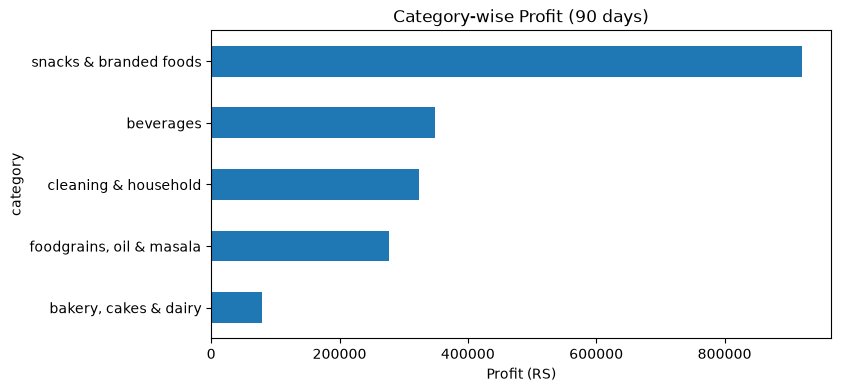

In [41]:
cat["profit"].sort_values().plot(kind="barh", figsize=(8, 4))
plt.title("Category-wise Profit (90 days)")
plt.xlabel("Profit (RS)")
plt.show()

In [42]:
kirana["days_cover"] = np.round(
    kirana["current_stock"] / kirana["daily_demand"].replace(0, np.nan), 1
)
kirana["days_cover"].describe()

count    600.00000
mean      60.25400
std       34.07108
min        0.00000
25%       33.27500
50%       59.55000
75%       89.37500
max      120.00000
Name: days_cover, dtype: float64

In [43]:
dead = kirana[kirana["days_cover"] > 90]

print("Dead stock products:", len(dead))
print("Money stuck in Dead stock", dead["stock_value"].sum())

dead.sort_values("stock_value", ascending=False)[
    ["sku_name", "category", "current_stock", "days_cover", "stock_value"]
].head(10)

Dead stock products: 149
Money stuck in Dead stock 2487303.6100000003


,sku_name,category,current_stock,days_cover,stock_value
125,&Stirred Weekend Party Pack - Get 2 pcs per pr...,beverages,161,107.3,126336.70
31,"MOI SOI Korean Chilli Oil - Vegan, Used As Spr...","foodgrains, oil & masala",539,96.9,93176.93
284,Prolicious Penne Durum Wheat Pasta - Rich In P...,snacks & branded foods,670,113.9,92982.60
113,"Typhoo Masala Tea, 50 g (25 Bags x 2 g each)",beverages,601,110.3,86958.69
234,"Gits Falooda Ready Mix - Badam & Pista, 200 g",snacks & branded foods,922,114.8,62262.66
387,"bb Gooddiet Chocolate Millet Pancake Mix, 150 g",snacks & branded foods,548,99.3,60345.76
156,NAARIO Organic Jaggery Powder With Chai Masala...,beverages,344,108.2,58424.96
436,"Triguni Eze Eats Vegetable Fried Rice, 115 g Tub",snacks & branded foods,448,97.4,48599.04
82,"Tasties Khari - Methi, 2x200 g Multipack","bakery, cakes & dairy",270,109.8,45281.70
229,"Hershey's Cookies N Creme Bar, 4 x 100 g Multi...",snacks & branded foods,125,117.9,43931.25


In [44]:
reorder = kirana[kirana["current_stock"] <= kirana["reorder_level"]].copy()

# 30 din ka stock rakhne ke liye kitna mangwana hai
reorder["order_qty"] = np.ceil(reorder["daily_demand"] * 30 - reorder["current_stock"]).astype(int)

print("Reorder products:", len(reorder))

reorder.sort_values("daily_demand", ascending=False)[
    ["sku_name", "current_stock", "reorder_level", "order_qty"]
].head(10)

Reorder products: 40


,sku_name,current_stock,reorder_level,order_qty
434,"Dukes Waffy Wafers - Vanilla Flavoured, Cream...",29,54,149
416,"Vandys Makhana Minty Limon - Snack, Rich In An...",23,45,111
413,"MAGGI Cuppa Noodles - Masala, Quick On-The-Go...",16,27,84
423,"Double Horse Vermicelli Kheer Mix, 300 g Box",12,27,77
293,"Crax Aloo Bhujia Namkeen, 2x160 g Multipack",26,29,61
445,"South fresh Idli & Dosa Batter, 425 ml",9,26,75
259,"Tasties Whole Wheat Khakhra Masala, 180 g",11,19,70
58,"ProV Premium Black Raisin - Natural, Seedless,...",6,14,52
148,"Minute Maid Juice - Mixed Fruit, 1 L PET Bottle",13,13,40
25,Delicious Cashew/Godambis - Dry Roasted & Chee...,6,11,42


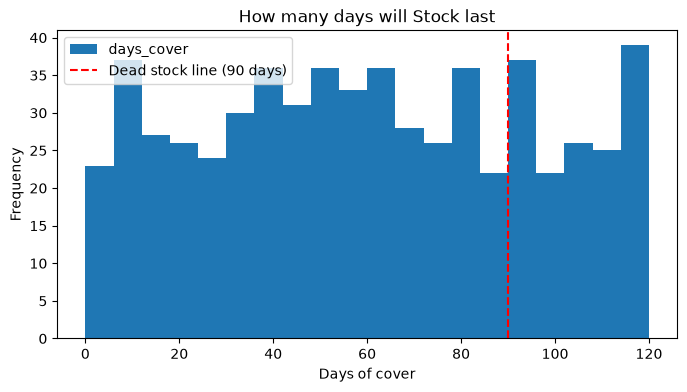

In [45]:
kirana["days_cover"].plot(kind="hist", bins=20, figsize=(8, 4))
plt.axvline(90, color="red", linestyle="--", label="Dead stock line (90 days)")
plt.title("How many days will Stock last")
plt.xlabel("Days of cover")
plt.legend()
plt.show()

In [46]:
sales_cut = kirana["units_sold_90d"].median()

def stock_status(row):
    if row["days_cover"] > 90:
        if row["units_sold_90d"] >= sales_cut:
            return "Overstock (fast)"
        return "Dead/Slow stock"
    if row["current_stock"] <= row["reorder_level"]:
        return "Reorder now"
    return "Healthy"

kirana["stock_status"] = kirana.apply(stock_status, axis=1)

print(kirana["stock_status"].value_counts())
print(kirana.groupby("stock_status")["stock_value"].sum().round(0))

stock_status
Healthy             411
Dead/Slow stock      76
Overstock (fast)     73
Reorder now          40
Name: count, dtype: int64
stock_status
Dead/Slow stock      701110.0
Healthy             3020733.0
Overstock (fast)    1786194.0
Reorder now           26634.0
Name: stock_value, dtype: float64


In [47]:
abc = kirana.sort_values("profit_90d", ascending=False).reset_index(drop=True)

abc["cum_profit_pct"] = abc["profit_90d"].cumsum() / abc["profit_90d"].sum() * 100
abc["abc_class"] = np.where(abc["cum_profit_pct"] <= 70, "A",
                   np.where(abc["cum_profit_pct"] <= 90, "B", "C"))

summary = abc.groupby("abc_class").agg(
    products=("sku_name", "count"),
    profit=("profit_90d", "sum"),
    stock_value=("stock_value", "sum"),
)
summary["product_%"] = np.round(summary["products"] / len(abc) * 100, 1)
summary["profit_%"] = np.round(summary["profit"] / summary["profit"].sum() * 100, 1)
summary["stock_%"] = np.round(summary["stock_value"] / summary["stock_value"].sum() * 100, 1)
summary

,products,profit,stock_value,product_%,profit_%,stock_%
abc_class,,,,,,
A,197,1363089.27,3564872.62,32.8,70.0,64.4
B,169,389024.60,1190457.76,28.2,20.0,21.5
C,234,195867.66,779340.51,39.0,10.1,14.1


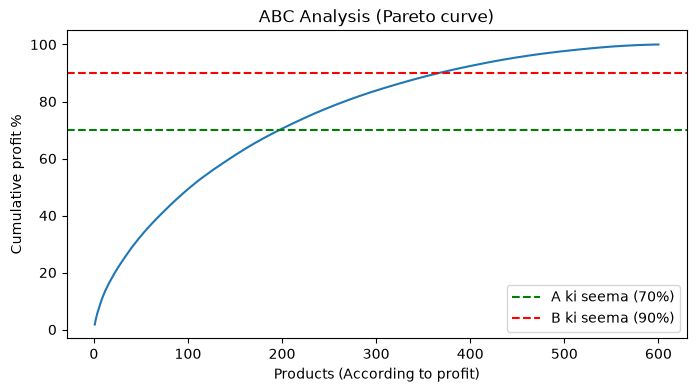

In [48]:
kirana = kirana.merge(abc[["product_link", "abc_class"]], on="product_link", how="left")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(abc) + 1), abc["cum_profit_pct"])
plt.axhline(70, color="green", linestyle="--", label="A ki seema (70%)")
plt.axhline(90, color="red", linestyle="--", label="B ki seema (90%)")
plt.title("ABC Analysis (Pareto curve)")
plt.xlabel("Products (According to profit)")
plt.ylabel("Cumulative profit %")
plt.legend()
plt.show()

kirana.to_csv("kirana_final.csv", index=False)

In [49]:
# 1. Kitne products
print(pd.crosstab(kirana["abc_class"], kirana["stock_status"]))

# 2. Kitna paisa (₹ lakh mein)
money = pd.crosstab(
    kirana["abc_class"], kirana["stock_status"],
    values=kirana["stock_value"], aggfunc="sum"
) / 100000
print(money.round(2))

stock_status  Dead/Slow stock  Healthy  Overstock (fast)  Reorder now
abc_class                                                            
A                          10      140                39            8
B                          22      109                23           15
C                          44      162                11           17
stock_status  Dead/Slow stock  Healthy  Overstock (fast)  Reorder now
abc_class                                                            
A                        1.84    19.79             13.92         0.10
B                        2.95     5.92              2.93         0.10
C                        2.22     4.50              1.01         0.07


In [50]:
# Maan lo hum sirf 45 din ka stock rakhna chahte hain
target_days = 45
kirana["target_stock"] = np.ceil(kirana["daily_demand"] * target_days)
kirana["excess_units"] = (kirana["current_stock"] - kirana["target_stock"]).clip(lower=0)
kirana["excess_value"] = kirana["excess_units"] * kirana["cost_price"]

print("Money stuck in unwanted stock:", round(kirana["excess_value"].sum()))
print(kirana.groupby("abc_class")["excess_value"].sum().round(0))

Money stuck in unwanted stock: 2089860
abc_class
A    1351413.0
B     452091.0
C     286355.0
Name: excess_value, dtype: float64


In [51]:
# Kitna mangwana hai (30 din ke stock tak)
kirana["order_qty"] = np.ceil(
    kirana["daily_demand"] * 30 - kirana["current_stock"]
).clip(lower=0).astype(int)

cols = ["sku_name", "category", "abc_class", "current_stock", "reorder_level", "order_qty"]

# 1. Abhi order do (A class pehle, kyunki wahi kamaai dete hain)
reorder_list = (kirana[kirana["stock_status"] == "Reorder now"]
                .sort_values(["abc_class", "daily_demand"], ascending=[True, False])[cols])

# 2. Order roko: A class ke overstock products
stop_order = (kirana[(kirana["stock_status"] == "Overstock (fast)") & (kirana["abc_class"] == "A")]
              .sort_values("excess_value", ascending=False)
              [["sku_name", "category", "current_stock", "days_cover", "excess_value"]])

# 3. Discount karke nikalo: C class ka dead/slow stock
clearance = (kirana[(kirana["stock_status"] == "Dead/Slow stock") & (kirana["abc_class"] == "C")]
             .sort_values("stock_value", ascending=False)
             [["sku_name", "category", "current_stock", "days_cover", "stock_value"]])

print(len(reorder_list), len(stop_order), len(clearance))

40 39 44


In [52]:
with pd.ExcelWriter("kirana_action_plan.xlsx") as writer:
    reorder_list.to_excel(writer, sheet_name="Reorder now", index=False)
    stop_order.to_excel(writer, sheet_name="Stop ordering", index=False)
    clearance.to_excel(writer, sheet_name="Clearance", index=False)

kirana.to_csv("kirana_final.csv", index=False)

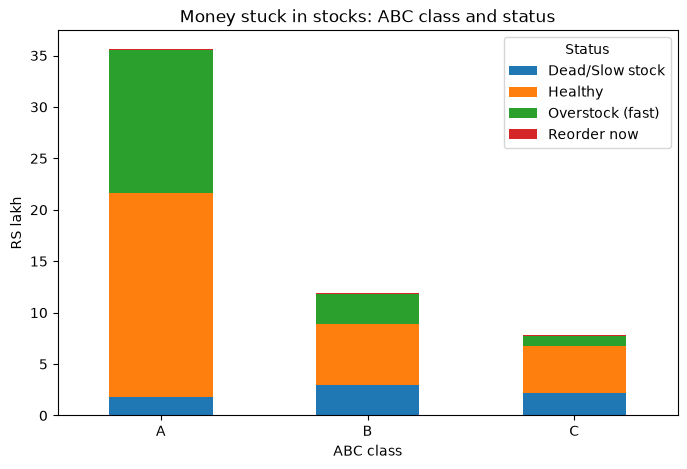

In [53]:
money.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Money stuck in stocks: ABC class and status")
plt.xlabel("ABC class")
plt.ylabel("RS lakh")
plt.xticks(rotation=0)
plt.legend(title="Status")
plt.show()